# Rozwiązania wzorcowe: rejestracja elastyczna (niesztywna) obrazów medycznych

Ten notatnik zawiera **kompletne, gotowe do uruchomienia rozwiązania** obu zadań z zeszytu `zadania_rejestracja_elastyczna.ipynb`:

1. **Zadanie 1 — Angiografia nerkowa (`stent.jpg`):** rejestracja elastyczna `BSplineTransform` korygująca lokalne przesunięcie i rozciągnięcie dystalnego drzewa tętniczego lewej nerki.
2. **Zadanie 2 — Tomografia komputerowa jamy brzusznej (`img-Pyelonephritis-kidney-follow-up-9070.jpeg`):** dopasowanie obrzękniętej zapalnie prawej nerki (*pyelonephritis*) oraz przeniesienie jej maski segmentacyjnej (`Mask Propagation`) z oceną **współczynnika Dice'a**.

In [3]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK

import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

def dice_score(mask1, mask2):
    """Oblicza współczynnik podobieństwa Dice'a dla dwóch masek binarnych SimpleITK."""
    m1 = sitk.GetArrayFromImage(mask1) > 0
    m2 = sitk.GetArrayFromImage(mask2) > 0
    return 2.0 * np.sum(m1 & m2) / (np.sum(m1) + np.sum(m2) + 1e-8)

def plot_bspline_results(fixed_img, moving_img, registered_img, bspline_transform,
                         fixed_mask=None, registered_mask=None, step=24):
    """Wyświetla 4-panelową diagnostykę rejestracji elastycznej."""
    f_arr = sitk.GetArrayFromImage(fixed_img)
    m_arr = sitk.GetArrayFromImage(moving_img)
    r_arr = sitk.GetArrayFromImage(registered_img)
    H, W = f_arr.shape
    yy, xx = np.mgrid[0:H, 0:W]

    # Ekstrakcja pola wektorowego przesunięć z transformacji B-splajn
    df_filter = sitk.TransformToDisplacementFieldFilter()
    df_filter.SetReferenceImage(fixed_img)
    est_df_np = sitk.GetArrayFromImage(df_filter.Execute(bspline_transform))

    fig, ax = plt.subplots(1, 4, figsize=(19, 4.8))

    # Panel 1: Różnica PRZED
    ax[0].imshow(f_arr - m_arr, cmap='bwr', vmin=-0.4, vmax=0.4)
    ax[0].set_title('1. Różnica PRZED rejestracją')

    # Panel 2: Różnica PO
    ax[1].imshow(f_arr - r_arr, cmap='bwr', vmin=-0.4, vmax=0.4)
    ax[1].set_title('2. Różnica PO rejestracji')

    # Panel 3: Pole wektorowe odkształceń
    ax[2].imshow(f_arr, cmap='gray', alpha=0.65)
    ax[2].quiver(
        xx[::step, ::step], yy[::step, ::step],
        est_df_np[::step, ::step, 0], est_df_np[::step, ::step, 1],
        color='yellow', angles='xy', scale_units='xy', scale=0.7
    )
    ax[2].set_title('3. Pole wektorowe odkształceń')

    # Panel 4: Odkształcona siatka B-splajn lub kontury przeniesionej maski
    if fixed_mask is not None and registered_mask is not None:
        ax[3].imshow(f_arr, cmap='gray')
        ax[3].contour(sitk.GetArrayFromImage(fixed_mask), colors='lime', linewidths=1.5, linestyles='--')
        ax[3].contour(sitk.GetArrayFromImage(registered_mask), colors='red', linewidths=1.2)
        ax[3].set_title('4. Maska (Zielony=Cel, Czerwony=Po)')
    else:
        grid_np = np.zeros_like(f_arr)
        grid_np[::22, :] = 1.0
        grid_np[:, ::22] = 1.0
        grid_img = sitk.GetImageFromArray(grid_np)
        grid_img.CopyInformation(fixed_img)
        warped_grid = sitk.Resample(grid_img, fixed_img, bspline_transform, sitk.sitkLinear, 0.0, grid_img.GetPixelID())
        ax[3].imshow(sitk.GetArrayFromImage(warped_grid), cmap='gray')
        ax[3].set_title('4. Zdeformowana siatka B-splajn')

    plt.tight_layout()
    plt.show()

print(f"Środowisko gotowe (SimpleITK {sitk.__version__})")

Środowisko gotowe (SimpleITK 2.5.7)


---
## ZADANIE 1 (ROZWIĄZANIE): Angiografia nerkowa (`stent.jpg`) — lokalna deformacja drzewa naczyniowego

* Używamy siatki `transformDomainMeshSize=[8, 8]` z wielomianami B-sklejanymi 3. stopnia (`order=3`), co daje $(8+3) \times (8+3) \times 2 = 242$ parametry — wystarczająco dużo, aby uchwycić krzywiznę rozgałęzień tętniczych po prawej stronie, ale na tyle rzadko, by uniknąć zawijania się siatki.
* Optymalizator **L-BFGS-B** skutecznie optymalizuje ponad 200 parametrów jednocześnie, a piramida wielorozdzielcza (`[4, 2, 1]`) najpierw wyrównuje główne pnie naczyniowe, a następnie doprecyzowuje drobne rozgałęzienia.

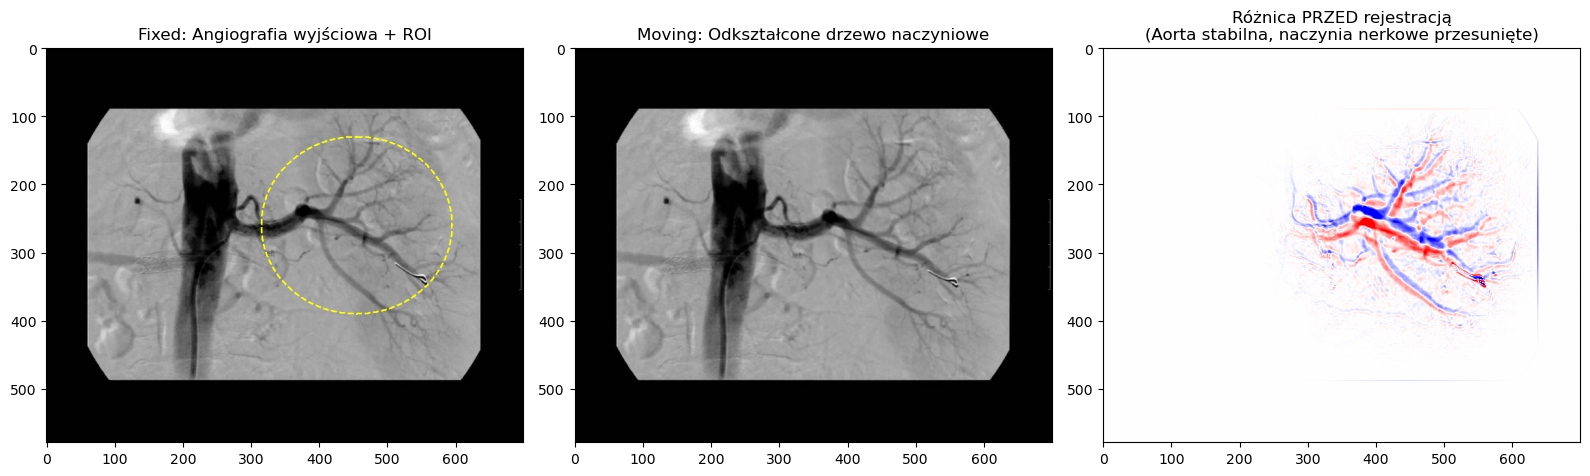

In [5]:
# 1. Wczytanie obrazu oryginalnego (Fixed) oraz wygenerowanie obrazu odkształconego (Moving)
fixed_stent_raw = sitk.ReadImage("sample photos/jpeg/stent.jpg", sitk.sitkFloat32)
fixed_stent = sitk.Cast(fixed_stent_raw / 255.0, sitk.sitkFloat32)
fixed_stent.SetSpacing((1.0, 1.0))
fixed_stent.SetOrigin((0.0, 0.0))

# Generowanie lokalnego odkształcenia drzewa naczyniowego (pole wektorowe Gaussa po prawej stronie)
f_stent_np = sitk.GetArrayFromImage(fixed_stent)
H1, W1 = f_stent_np.shape
y1, x1 = np.mgrid[0:H1, 0:W1].astype(np.float32)

cx1, cy1, sigma1 = 455.0, 260.0, 68.0
gauss1 = np.exp(-((x1 - cx1)**2 + (y1 - cy1)**2) / (2.0 * sigma1**2))
disp_x1 = -0.14 * (x1 - cx1) * gauss1 - 5.0 * gauss1
disp_y1 = -20.0 * gauss1 - 0.10 * (y1 - cy1) * gauss1

m_stent_np = map_coordinates(f_stent_np, [y1 + disp_y1, x1 + disp_x1], order=1, mode='nearest')
moving_stent = sitk.GetImageFromArray(m_stent_np.astype(np.float32))
moving_stent.CopyInformation(fixed_stent)

# Obszar zainteresowania (ROI) wokół rozgałęzień tętnicy nerkowej
roi_stent = (((x1 - 455.0) / 140.0)**2 + ((y1 - 260.0) / 130.0)**2) <= 1.0

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].imshow(f_stent_np, cmap='gray', vmin=0, vmax=1)
ax[0].contour(roi_stent, colors='yellow', linestyles='--', linewidths=1.2)
ax[0].set_title('Fixed: Angiografia wyjściowa + ROI')

ax[1].imshow(m_stent_np, cmap='gray', vmin=0, vmax=1)
ax[1].set_title('Moving: Odkształcone drzewo naczyniowe')

ax[2].imshow(f_stent_np - m_stent_np, cmap='bwr', vmin=-0.4, vmax=0.4)
ax[2].set_title('Różnica PRZED rejestracją\n(Aorta stabilna, naczynia nerkowe przesunięte)')
plt.tight_layout()
plt.show()

Uruchamiam rejestrację elastyczną angiografii (Zadanie 1)...
Zakończono! Powód zatrzymania: LBFGSBOptimizerv4: Gradient tolerance reached. Gradient tolerance is 1e-05
Zadanie 1 — Błąd MSE wewnątrz ROI PRZED rejestracją: 0.011515
Zadanie 1 — Błąd MSE wewnątrz ROI PO rejestracji:    0.001572


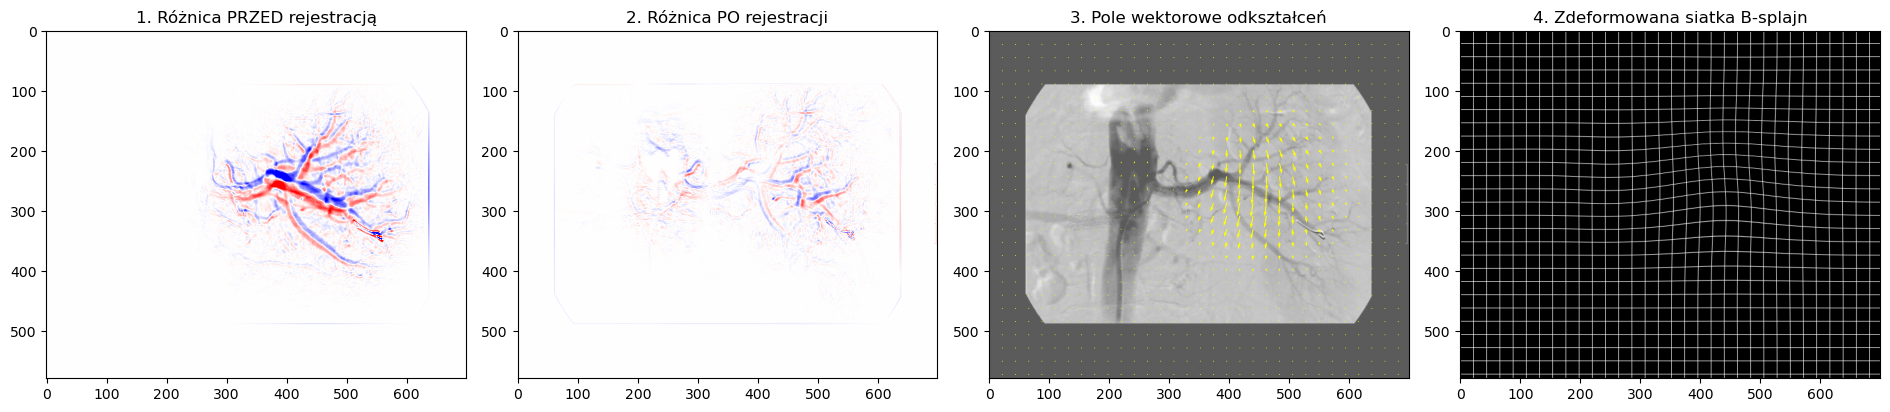

In [7]:
# ---------------------------------------------------------
# ROZWIĄZANIE WZORCOWE (Zadanie 1 - Rejestracja Elastyczna DSA)
# ---------------------------------------------------------

# 1. Inicjalizacja siatki punktów kontrolnych B-splajn (8x8 oczek, splajny 3. stopnia)
initial_bspline_stent = sitk.BSplineTransformInitializer(
    image1=fixed_stent,
    transformDomainMeshSize=[8, 8],
    order=3
)

R_stent = sitk.ImageRegistrationMethod()

# 2. Metryka MeanSquares (rejestracja jednomodalna DSA -> DSA) oraz optymalizator L-BFGS-B
R_stent.SetMetricAsMeanSquares()
R_stent.SetOptimizerAsLBFGSB(
    gradientConvergenceTolerance=1e-5,
    numberOfIterations=100,
    maximumNumberOfCorrections=5,
    maximumNumberOfFunctionEvaluations=1000,
    costFunctionConvergenceFactor=1e7
)

# 3. Interpolator liniowy oraz przypisanie transformacji początkowej
R_stent.SetInterpolator(sitk.sitkLinear)
R_stent.SetInitialTransform(initial_bspline_stent, inPlace=False)

# 4. Piramida wielorozdzielcza dla płynnej zbieżności
R_stent.SetShrinkFactorsPerLevel(shrinkFactors=[4, 2, 1])
R_stent.SetSmoothingSigmasPerLevel(smoothingSigmas=[2, 1, 0])
R_stent.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

# 5. Uruchomienie rejestracji elastycznej
print("Uruchamiam rejestrację elastyczną angiografii (Zadanie 1)...")
final_bspline_stent = R_stent.Execute(fixed_stent, moving_stent)
print(f"Zakończono! Powód zatrzymania: {R_stent.GetOptimizerStopConditionDescription()}")

# =========================================================
# WERYFIKACJA WYNIKU DLA ZADANIA 1
# =========================================================
registered_stent = sitk.Resample(moving_stent, fixed_stent, final_bspline_stent, sitk.sitkLinear, 0.0, moving_stent.GetPixelID())
r_stent_np = sitk.GetArrayFromImage(registered_stent)

mse_before = np.mean((f_stent_np[roi_stent] - m_stent_np[roi_stent])**2)
mse_after = np.mean((f_stent_np[roi_stent] - r_stent_np[roi_stent])**2)
print(f"Zadanie 1 — Błąd MSE wewnątrz ROI PRZED rejestracją: {mse_before:.6f}")
print(f"Zadanie 1 — Błąd MSE wewnątrz ROI PO rejestracji:    {mse_after:.6f}")

plot_bspline_results(fixed_stent, moving_stent, registered_stent, final_bspline_stent, step=22)

---
## ZADANIE 2 (ROZWIĄZANIE): TK jamy brzusznej (`img-Pyelonephritis-kidney-follow-up-9070.jpeg`) — obrzęk zapalny prawej nerki

* Kluczowym elementem kroku 6 jest rozróżnienie metod interpolacji podczas wywoływania funkcji `sitk.Resample()`:
  * Dla obrazu TK (`moving_kidney`) stosujemy **`sitk.sitkLinear`**, aby zachować gładkie przejścia skali szarości miąższu nerki.
  * Dla binarnej maski nerki (`moving_mask_kidney`) stosujemy **`sitk.sitkNearestNeighbor`**, aby nie wprowadzać ułamkowych wartości pośrednich na granicach segmentacji.
* Na panelu 3 (*Pole wektorowe odkształceń*) wektory przesunięć skupiają się wyłącznie w obrębie prawej nerki, podczas gdy nad kręgosłupem lędźwiowym i kością miedniczną pozostają bliskie zeru.

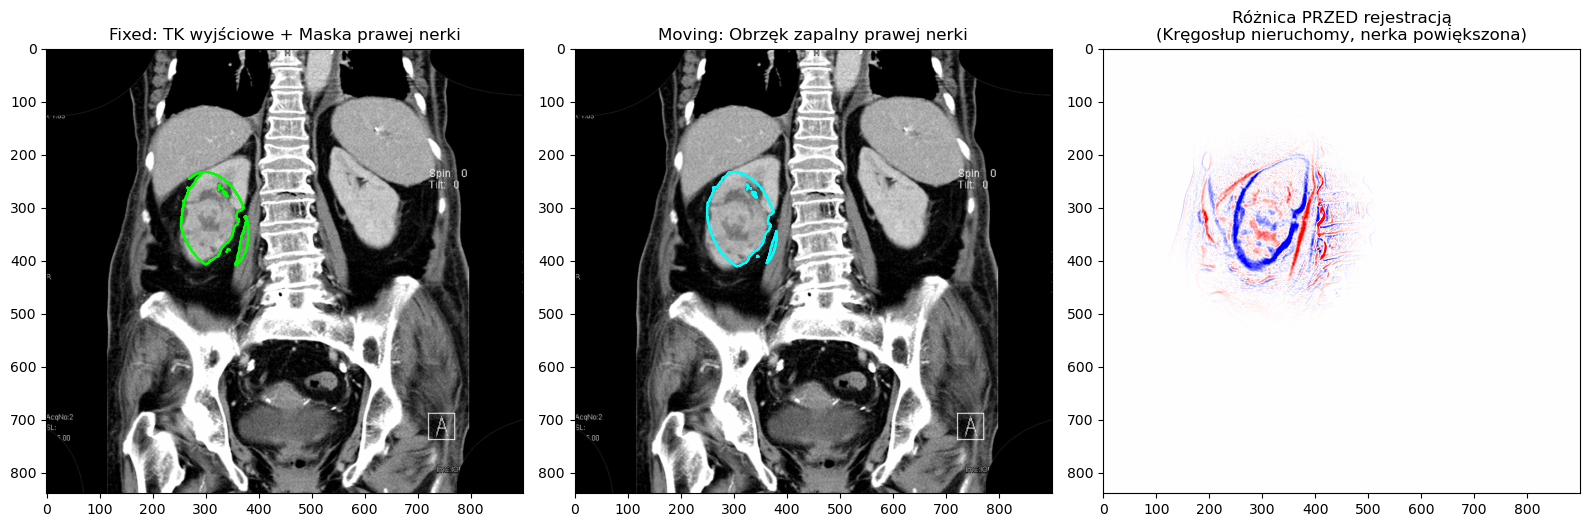

In [10]:
# 1. Wczytanie skanu TK (Fixed) oraz wygenerowanie skanu kontrolnego z obrzękiem prawej nerki (Moving)
fixed_kidney_raw = sitk.ReadImage("sample photos/jpeg/img-Pyelonephritis-kidney-follow-up-9070.jpeg", sitk.sitkFloat32)
fixed_kidney = sitk.Cast(fixed_kidney_raw / 255.0, sitk.sitkFloat32)
fixed_kidney.SetSpacing((1.0, 1.0))
fixed_kidney.SetOrigin((0.0, 0.0))

f_kidney_np = sitk.GetArrayFromImage(fixed_kidney)
H2, W2 = f_kidney_np.shape
y2, x2 = np.mgrid[0:H2, 0:W2].astype(np.float32)

# Lokalny obrzęk (ekspansja radialna) i przesunięcie prawej nerki (x=315, y=325)
cx2, cy2, sigma2 = 315.0, 325.0, 55.0
gauss2 = np.exp(-((x2 - cx2)**2 + (y2 - cy2)**2) / (2.0 * sigma2**2))
disp_x2 = -0.25 * (x2 - cx2) * gauss2 + 3.0 * gauss2
disp_y2 = -0.24 * (y2 - cy2) * gauss2 - 14.0 * gauss2

m_kidney_np = map_coordinates(f_kidney_np, [y2 + disp_y2, x2 + disp_x2], order=1, mode='nearest')
moving_kidney = sitk.GetImageFromArray(m_kidney_np.astype(np.float32))
moving_kidney.CopyInformation(fixed_kidney)

# Maski segmentacyjne prawej nerki (Fixed oraz Moving) do oceny współczynnika Dice'a
theta = np.radians(-18.0)
xr = (x2 - 315.0) * np.cos(theta) + (y2 - 325.0) * np.sin(theta)
yr = -(x2 - 315.0) * np.sin(theta) + (y2 - 325.0) * np.cos(theta)
kidney_roi = ((xr / 62.0)**2 + (yr / 95.0)**2) <= 1.0

fixed_mask_np = (kidney_roi & (f_kidney_np > 0.25)).astype(np.uint8)
moving_mask_np = (kidney_roi & (m_kidney_np > 0.25)).astype(np.uint8)

fixed_mask_kidney = sitk.GetImageFromArray(fixed_mask_np)
fixed_mask_kidney.CopyInformation(fixed_kidney)
moving_mask_kidney = sitk.GetImageFromArray(moving_mask_np)
moving_mask_kidney.CopyInformation(fixed_kidney)

fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
ax[0].imshow(f_kidney_np, cmap='gray', vmin=0, vmax=1)
ax[0].contour(fixed_mask_np, colors='lime', linewidths=1.2)
ax[0].set_title('Fixed: TK wyjściowe + Maska prawej nerki')

ax[1].imshow(m_kidney_np, cmap='gray', vmin=0, vmax=1)
ax[1].contour(moving_mask_np, colors='cyan', linewidths=1.2)
ax[1].set_title('Moving: Obrzęk zapalny prawej nerki')

ax[2].imshow(f_kidney_np - m_kidney_np, cmap='bwr', vmin=-0.4, vmax=0.4)
ax[2].set_title('Różnica PRZED rejestracją\n(Kręgosłup nieruchomy, nerka powiększona)')
plt.tight_layout()
plt.show()

Uruchamiam rejestrację elastyczną skanu TK nerki (Zadanie 2)...
Zakończono! Powód zatrzymania: LBFGSBOptimizerv4: Gradient tolerance reached. Gradient tolerance is 1e-05
Zadanie 2 — Współczynnik Dice maski nerki PRZED rejestracją: 0.9229
Zadanie 2 — Współczynnik Dice maski nerki PO rejestracji:    0.9378


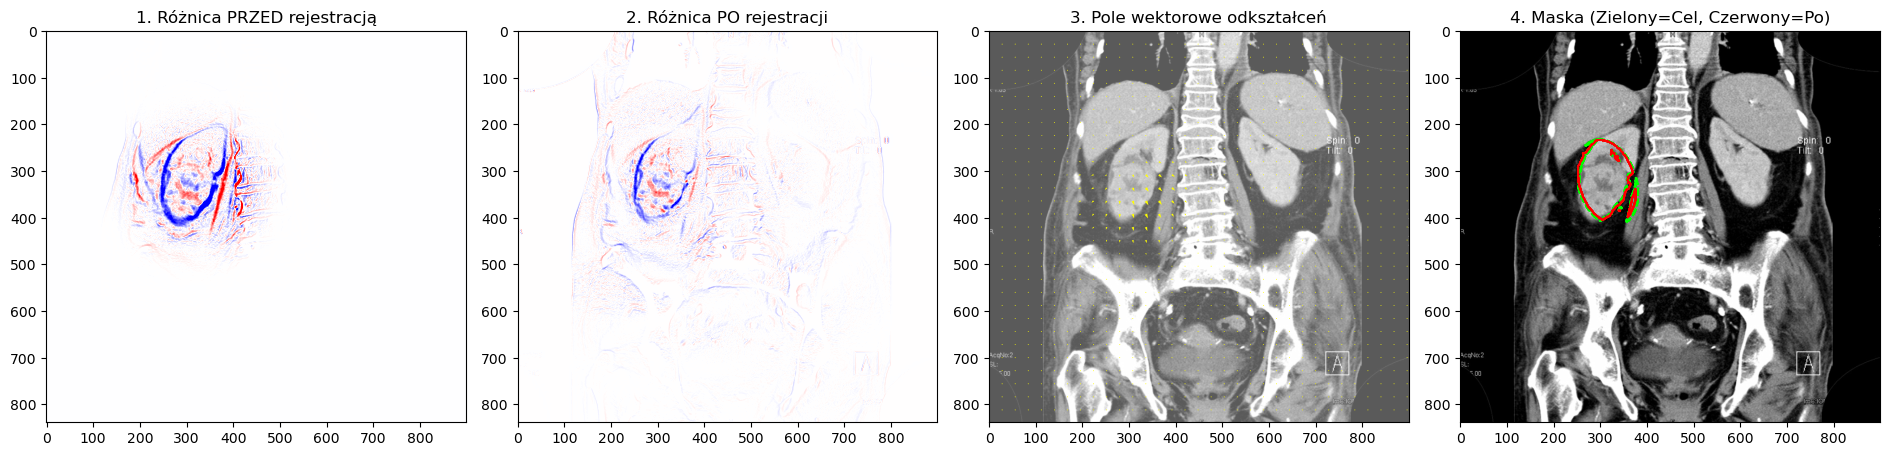

In [12]:
# ---------------------------------------------------------
# ROZWIĄZANIE WZORCOWE (Zadanie 2 - Rejestracja Elastyczna TK Nerki)
# ---------------------------------------------------------

# 1. Inicjalizacja siatki B-splajn (8x8 oczek, order=3)
initial_bspline_kidney = sitk.BSplineTransformInitializer(
    image1=fixed_kidney,
    transformDomainMeshSize=[8, 8],
    order=3
)

R_kidney = sitk.ImageRegistrationMethod()

# 2. Metryka MeanSquares oraz optymalizator L-BFGS-B
R_kidney.SetMetricAsMeanSquares()
R_kidney.SetOptimizerAsLBFGSB(
    gradientConvergenceTolerance=1e-5,
    numberOfIterations=100,
    maximumNumberOfCorrections=5,
    maximumNumberOfFunctionEvaluations=1000,
    costFunctionConvergenceFactor=1e7
)

# 3. Interpolator liniowy i transformacja początkowa
R_kidney.SetInterpolator(sitk.sitkLinear)
R_kidney.SetInitialTransform(initial_bspline_kidney, inPlace=False)

# 4. Piramida wielorozdzielcza ([4, 2, 1] oraz sigmy [2, 1, 0])
R_kidney.SetShrinkFactorsPerLevel(shrinkFactors=[4, 2, 1])
R_kidney.SetSmoothingSigmasPerLevel(smoothingSigmas=[2, 1, 0])
R_kidney.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

# 5. Wykonanie rejestracji elastycznej
print("Uruchamiam rejestrację elastyczną skanu TK nerki (Zadanie 2)...")
final_bspline_kidney = R_kidney.Execute(fixed_kidney, moving_kidney)
print(f"Zakończono! Powód zatrzymania: {R_kidney.GetOptimizerStopConditionDescription()}")

# 6. Resampling obrazu TK (sitkLinear) ORAZ binarnej maski nerki (sitkNearestNeighbor)
registered_kidney = sitk.Resample(
    moving_kidney, fixed_kidney, final_bspline_kidney,
    sitk.sitkLinear, 0.0, moving_kidney.GetPixelID()
)
registered_mask_kidney = sitk.Resample(
    moving_mask_kidney, fixed_kidney, final_bspline_kidney,
    sitk.sitkNearestNeighbor, 0, moving_mask_kidney.GetPixelID()
)

# =========================================================
# WERYFIKACJA WYNIKU I WSPÓŁCZYNNIKA DICE'A DLA ZADANIA 2
# =========================================================
print(f"Zadanie 2 — Współczynnik Dice maski nerki PRZED rejestracją: {dice_score(fixed_mask_kidney, moving_mask_kidney):.4f}")
print(f"Zadanie 2 — Współczynnik Dice maski nerki PO rejestracji:    {dice_score(fixed_mask_kidney, registered_mask_kidney):.4f}")

plot_bspline_results(
    fixed_kidney, moving_kidney, registered_kidney, final_bspline_kidney,
    fixed_mask=fixed_mask_kidney, registered_mask=registered_mask_kidney, step=28
)